# Descriptive Statistics  
Data Handling:
1. Import Data
2. Data cleaning

Describe Dataset with:  
1. Shape (number of column & row)
2. Data type & Null in each column
3. Continuous data vs Discrete data
4. Range / Mean / Mode / Median
5. Percentiles & Quartiles
6. Plot Graph

## Sample Data 1   
Dataset Name: Daily Maximum Temperature All Year - Hong Kong International Airport  
FileName: CLMMAXT_HKA_.csv  
Source: https://data.gov.hk/en-data/dataset/hk-hko-rss-daily-temperature-info-hko/resource/c09f74da-6dee-46ce-ac6b-3bdb92070e0a

In [92]:
import pandas as pd
import numpy as np
#Import csv from to dataframe
file_path='CLMMAXT_HKA_.csv'
df = pd.read_csv(file_path, skiprows=2) #First 2 rows are NOT Field name
#Rename Column name for later use
df.rename(columns={"年/Year":"Year","月/Month":"Month","日/Day":"Day","數值/Value":"Value","數據完整性/data Completeness":"data_completeness"},inplace=True)
display(df)

,Year,Month,Day,Value,data_completeness
0,1997,6.0,1.0,***,#
1,1997,6.0,2.0,***,#
2,1997,6.0,3.0,31.7,#
3,1997,6.0,4.0,30.2,#
4,1997,6.0,5.0,***,#
...,...,...,...,...,...
10682,2026,8.0,30.0,32.3,C
10683,2026,8.0,31.0,31.2,C
10684,*** 沒有數據/unavailable,NaN,NaN,NaN,NaN
10685,# 數據不完整/data incomplete,NaN,NaN,NaN,NaN


In [93]:
#Check the Shape of df
print(df.shape) #10687,5

(10687, 5)


In [94]:
#Check basic info
df.info()
## We can find that only first column has 10687, need to check the bottom data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10687 entries, 0 to 10686
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10687 non-null  object 
 1   Month              10684 non-null  float64
 2   Day                10684 non-null  float64
 3   Value              10684 non-null  object 
 4   data_completeness  10684 non-null  object 
dtypes: float64(2), object(3)
memory usage: 417.6+ KB


In [95]:
#Unexpected records in last 3 rows
display(df.tail())

,Year,Month,Day,Value,data_completeness
10682,2026,8.0,30.0,32.3,C
10683,2026,8.0,31.0,31.2,C
10684,*** 沒有數據/unavailable,NaN,NaN,NaN,NaN
10685,# 數據不完整/data incomplete,NaN,NaN,NaN,NaN
10686,C 數據完整/data Complete,NaN,NaN,NaN,NaN


In [96]:
#Before Study remove last 3 rows
df_cleaned=df.drop(df.tail(3).index, inplace = False).copy()
display(df_cleaned)
display(df_cleaned.tail())

,Year,Month,Day,Value,data_completeness
0,1997,6.0,1.0,***,#
1,1997,6.0,2.0,***,#
2,1997,6.0,3.0,31.7,#
3,1997,6.0,4.0,30.2,#
4,1997,6.0,5.0,***,#
...,...,...,...,...,...
10679,2026,8.0,27.0,30.7,C
10680,2026,8.0,28.0,32.6,C
10681,2026,8.0,29.0,33.3,C
10682,2026,8.0,30.0,32.3,C


,Year,Month,Day,Value,data_completeness
10679,2026,8.0,27.0,30.7,C
10680,2026,8.0,28.0,32.6,C
10681,2026,8.0,29.0,33.3,C
10682,2026,8.0,30.0,32.3,C
10683,2026,8.0,31.0,31.2,C


In [97]:
#Check Shape & info of df_cleaned
print(df_cleaned.shape) #10684,5
df_cleaned.info()

(10684, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10684 entries, 0 to 10683
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               10684 non-null  object 
 1   Month              10684 non-null  float64
 2   Day                10684 non-null  float64
 3   Value              10684 non-null  object 
 4   data_completeness  10684 non-null  object 
dtypes: float64(2), object(3)
memory usage: 417.5+ KB


In [98]:
# [Year] suppose nuumber type & [Value] suppose number type
## Check Unique value in [Year] & [Value]
print(df_cleaned.Year.unique())
print(df_cleaned.Value.unique())


['1997' '1998' '1999' '2000' '2001' '2002' '2003' '2004' '2005' '2006'
 '2007' '2008' '2009' '2010' '2011' '2012' '2013' '2014' '2015' '2016'
 '2017' '2018' '2019' '2020' '2021' '2022' '2023' '2024' '2025' '2026']
['***' '31.7' '30.2' '32.0' '30.3' '26.8' '27.4' '31.0' '28.8' '28.9'
 '26.3' '26.0' '26.2' '26.9' '31.4' '31.2' '29.8' '32.8' '30.9' '29.0'
 '30.0' '30.5' '30.1' '31.5' '30.8' '29.9' '30.6' '32.1' '32.4' '28.3'
 '28.0' '31.6' '32.3' '33.3' '31.9' '33.4' '34.5' '29.3' '28.1' '31.3'
 '33.7' '32.2' '29.5' '31.1' '29.1' '32.7' '34.3' '35.1' '33.0' '34.6'
 '34.0' '33.2' '28.2' '28.7' '30.7' '29.2' '23.3' '25.9' '29.4' '25.0'
 '22.7' '23.4' '29.6' '28.6' '30.4' '29.7' '24.6' '21.8' '25.5' '26.1'
 '24.3' '25.3' '27.5' '27.0' '20.5' '20.2' '24.4' '26.6' '25.6' '22.8'
 '24.7' '16.8' '17.8' '21.6' '23.8' '19.1' '17.5' '17.2' '15.4' '15.0'
 '21.1' '24.0' '24.2' '22.6' '21.2' '17.6' '22.0' '22.5' '23.1' '23.5'
 '22.4' '23.2' '18.4' '20.6' '24.1' '20.3' '25.8' '16.4' '18.5' '15.8'
 '14.6

In [99]:
#[Year] checked all are number, so we change data type to int
#[Month] & [Day] also change to int
df_cleaned['Year']=df_cleaned['Year'].astype(int)
df_cleaned['Month']=df_cleaned['Month'].astype(int)
df_cleaned['Day']=df_cleaned['Day'].astype(int)
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10684 entries, 0 to 10683
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               10684 non-null  int64 
 1   Month              10684 non-null  int64 
 2   Day                10684 non-null  int64 
 3   Value              10684 non-null  object
 4   data_completeness  10684 non-null  object
dtypes: int64(3), object(2)
memory usage: 417.5+ KB


In [100]:
#But [Value] has "***", according to source remark, "***" = unavailable
#We check which records has "***" value
display(df_cleaned[df_cleaned['Value']=='***'])
#Only 214 records have "***", the Latest records is 1/1/1998

,Year,Month,Day,Value,data_completeness
0,1997,6,1,***,#
1,1997,6,2,***,#
4,1997,6,5,***,#
7,1997,6,8,***,#
8,1997,6,9,***,#
24,1997,6,25,***,#
25,1997,6,26,***,#
26,1997,6,27,***,#
27,1997,6,28,***,#
28,1997,6,29,***,#


In [101]:
#For study only, Let's cut the data after 31/12/1999
print(df_cleaned[df_cleaned['Year']==2000]) #index of 1/1/2000 is 944
df_cleaned_cut=df_cleaned.loc[944:].copy() #Get data after index 944
display(df_cleaned_cut)
df_cleaned_cut['Value']=df_cleaned_cut['Value'].astype(float) #Change Value {temperature} to float
df_cleaned_cut.info()

      Year  Month  Day Value data_completeness
944   2000      1    1  23.1                 C
945   2000      1    2  24.3                 #
946   2000      1    3  23.9                 #
947   2000      1    4  23.0                 #
948   2000      1    5  25.9                 C
...    ...    ...  ...   ...               ...
1305  2000     12   27  23.3                 C
1306  2000     12   28  24.0                 C
1307  2000     12   29  21.4                 #
1308  2000     12   30  20.2                 C
1309  2000     12   31  20.2                 #

[366 rows x 5 columns]


,Year,Month,Day,Value,data_completeness
944,2000,1,1,23.1,C
945,2000,1,2,24.3,#
946,2000,1,3,23.9,#
947,2000,1,4,23.0,#
948,2000,1,5,25.9,C
...,...,...,...,...,...
10679,2026,8,27,30.7,C
10680,2026,8,28,32.6,C
10681,2026,8,29,33.3,C
10682,2026,8,30,32.3,C


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9740 entries, 944 to 10683
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               9740 non-null   int64  
 1   Month              9740 non-null   int64  
 2   Day                9740 non-null   int64  
 3   Value              9740 non-null   float64
 4   data_completeness  9740 non-null   object 
dtypes: float64(1), int64(3), object(1)
memory usage: 380.6+ KB


In [109]:
#1. Shape (number of column & row) - (9740,5)
print(df_cleaned_cut.shape)
#2. Data type & Null in each column
print(df_cleaned_cut.info())
#3. Continuous data vs Discrete data
for (columnName, columnData) in df_cleaned_cut.items():
    print('<-------->')
    print('Column Name : ', columnName)
    print('Unique Value : ', columnData.unique())
    #[Year], [Month], [Day],[data_completeness] = Category
    #[Value] = Continuous data
    

(9740, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9740 entries, 944 to 10683
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               9740 non-null   int64  
 1   Month              9740 non-null   int64  
 2   Day                9740 non-null   int64  
 3   Value              9740 non-null   float64
 4   data_completeness  9740 non-null   object 
dtypes: float64(1), int64(3), object(1)
memory usage: 380.6+ KB
None
<-------->
Column Name :  Year
Unique Value :  [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025 2026]
<-------->
Column Name :  Month
Unique Value :  [ 1  2  3  4  5  6  7  8  9 10 11 12]
<-------->
Column Name :  Day
Unique Value :  [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]
<-------->
Column Name :  Value
Unique Value :  [23.1 24.3 23.9

In [ ]:
#4. Range / Mean / Mode / Median
print(f"Range: {df_cleaned_cut['Value'].describe()['min']} - {df_cleaned_cut['Value'].describe()['max']}")
print(f"Mean: {df_cleaned_cut['Value'].describe()['mean']}")
print(f"Mode: {df_cleaned_cut['Value'].mode()[0]}")
print(f"Median: {df_cleaned_cut['Value'].median()}")
#5. Percentiles & Quartiles
print('<--------------------->')
print(f"10th percentile: {df_cleaned_cut['Value'].quantile(0.1)}")
print(f"20th percentile: {df_cleaned_cut['Value'].quantile(0.2)}")
print(f"80th percentile: {df_cleaned_cut['Value'].quantile(0.8)}")
print(f"90th percentile: {df_cleaned_cut['Value'].quantile(0.9)}")
print('<--------------------->')
print(f"1st Quartile: {df_cleaned_cut['Value'].quantile(0.25)}")
print(f"2nd Quartile: {df_cleaned_cut['Value'].quantile(0.5)}")
print(f"3th Quartile: {df_cleaned_cut['Value'].quantile(0.75)}")

Range: 7.9 - 37.7
Mean: 27.629722792607804
Mode: 32.9
Median: 28.8
<--------------------->
10th percentile: 19.6
20th percentile: 22.5
80th percentile: 32.9
90th percentile: 33.9
<--------------------->
1st Quartile: 23.6
2nd Quartile: 28.8
3th Quartile: 32.3


In [ ]:
#6. Plot Graph
#Since we need to do time series plot, add Date column in df_cleaned_cut first
df_cleaned_cut['date'] = pd.to_datetime(dict(year=df_cleaned_cut['Year'], month=df_cleaned_cut['Month'], day=df_cleaned_cut['Day']))
print(df_cleaned_cut)

       Year  Month  Day  Value data_completeness       date
944    2000      1    1   23.1                 C 2000-01-01
945    2000      1    2   24.3                 # 2000-01-02
946    2000      1    3   23.9                 # 2000-01-03
947    2000      1    4   23.0                 # 2000-01-04
948    2000      1    5   25.9                 C 2000-01-05
...     ...    ...  ...    ...               ...        ...
10679  2026      8   27   30.7                 C 2026-08-27
10680  2026      8   28   32.6                 C 2026-08-28
10681  2026      8   29   33.3                 C 2026-08-29
10682  2026      8   30   32.3                 C 2026-08-30
10683  2026      8   31   31.2                 C 2026-08-31

[9740 rows x 6 columns]


Text(0.5, 1.0, 'HKA Temperature during 2000 to 2026 Aug')

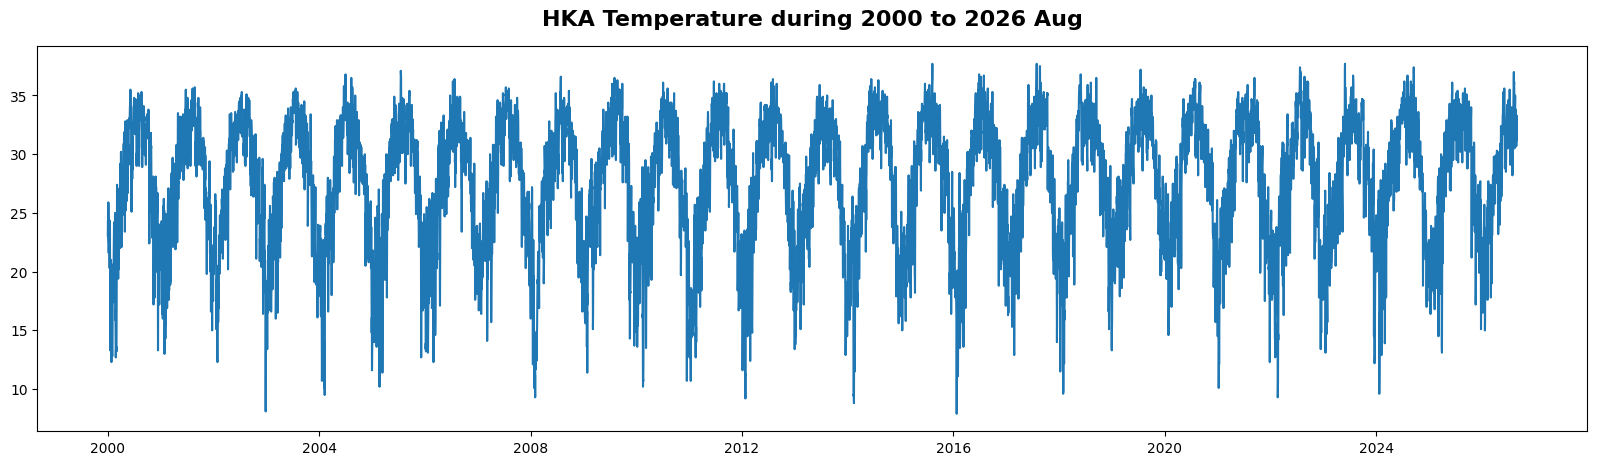

In [146]:
import matplotlib.pyplot as plt
#1st chart
plt.figure(figsize=(20, 5))
plt.plot(df_cleaned_cut['date'],df_cleaned_cut['Value'])
plt.title("HKA Temperature during 2000 to 2026 Aug", fontsize=16, fontweight='bold', pad=15)

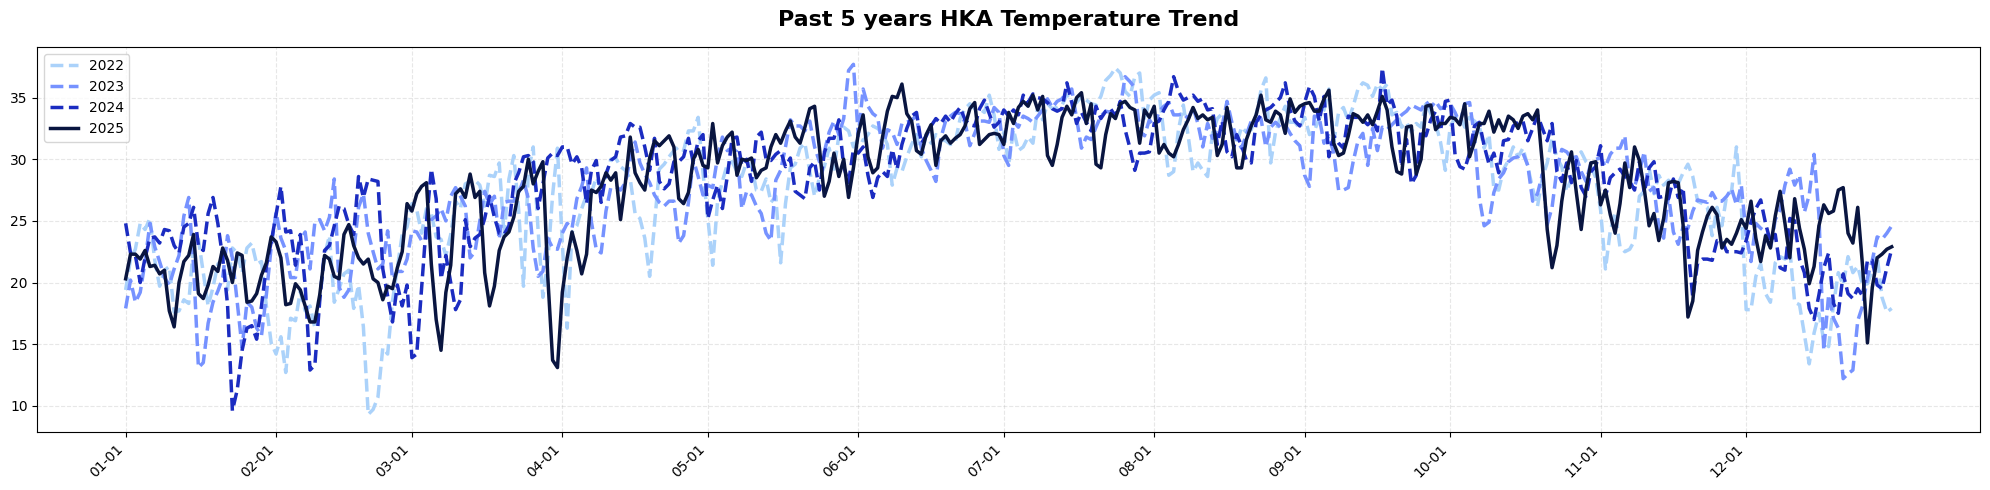

In [183]:
#2nd chart
plt.figure(figsize=(20, 5))
df_cleaned_cut['date_mm_dd']=df_cleaned_cut['date'].dt.strftime('%m-%d')
x_monthDay=df_cleaned_cut[df_cleaned_cut['date_mm_dd']!='02-29']['date_mm_dd'].unique().tolist() #Drop 02-29 to keep all list lengths are 365
y_2022=df_cleaned_cut[df_cleaned_cut['Year']==2022]['Value'].tolist()
y_2023=df_cleaned_cut[df_cleaned_cut['Year']==2023]['Value'].tolist()
y_2024=df_cleaned_cut[(df_cleaned_cut['Year']==2024) & (df_cleaned_cut['date_mm_dd']!='02-29')]['Value'].tolist() #366 days, deal to 29th Feb
y_2025=df_cleaned_cut[df_cleaned_cut['Year']==2025]['Value'].tolist()
plt.plot(x_monthDay, y_2022, color='#ABD2FA', linestyle='--',linewidth=2.5, label='2022')
plt.plot(x_monthDay, y_2023, color='#7692FF', linestyle='--',linewidth=2.5, label='2023')
plt.plot(x_monthDay, y_2024, color='#1B2CC1', linestyle='--',linewidth=2.5, label='2024')
plt.plot(x_monthDay, y_2025, color='#091540', linewidth=2.5, label='2025')
#Only show label in each 1st of Month
ticks_positions = [idx for idx, date in enumerate(x_monthDay) if date.endswith('-01')]
ticks_labels = [date for date in x_monthDay if date.endswith('-01')]
plt.xticks(ticks=ticks_positions, labels=ticks_labels, rotation=45, ha='right')
plt.title("Past 5 years HKA Temperature Trend", fontsize=16, fontweight='bold', pad=15)
plt.legend(loc='upper left')
plt.grid(axis='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


## Sample Data 2

Dataset Name: Table 310-31001 : Gross Domestic Product (GDP), implicit price deflator of GDP and per capita GDP  
FileName: /Table 310-31001 (tabular)_en/Table 310-31001.csv  
Source: https://www.censtatd.gov.hk/en/web_table.html?id=31#

In [ ]:
# First Read the supporting document (/Table 310-31001 (tabular)_en/Table_meta 310-31001.csv)
import pandas as pd
import numpy as np
file_path='./Table 310-31001 (tabular)_en/Table 310-31001.csv'
df = pd.read_csv(file_path)
display(df)

display(df.groupby(['STAT_VAR','STAT_PRES']).size()) 
#This time we use [CUR - GDP at current market prices] & [Raw_M_hkd_d - HK$ million] to do descriptive statistics


,STAT_VAR,STAT_PRES,CCYY,Q,OBS_VALUE,SD_VALUE
0,CUR,Raw_M_hkd_d,1961,NaN,7455.0,NaN
1,CUR,Raw_M_hkd_d,1962,NaN,8687.0,NaN
2,CUR,Raw_M_hkd_d,1963,NaN,10427.0,NaN
3,CUR,Raw_M_hkd_d,1964,NaN,11888.0,NaN
4,CUR,Raw_M_hkd_d,1965,NaN,13953.0,NaN
...,...,...,...,...,...,...
3064,DEF,YoY_1dp_%_s,2025,2.0,0.5,104
3065,DEF,YoY_1dp_%_s,2025,3.0,0.5,104
3066,DEF,YoY_1dp_%_s,2025,4.0,1.4,104
3067,DEF,YoY_1dp_%_s,2026,1.0,-0.2,104


STAT_VAR  STAT_PRES    
CON       Raw_M_hkd_d      279
          YoY_1dp_%_s      279
CONPGDP   Raw_hkd_d        279
          YoY_1dp_%_s      279
CUR       Raw_M_hkd_d      279
          YoY_1dp_%_s      279
CURPGDP   Raw_hkd_d        279
          YoY_1dp_%_s      279
DEF       Raw_1dp_idx_n    279
          YoY_1dp_%_s      279
SA1       QoQ_1dp_%_s      279
dtype: int64

In [ ]:
#Filter STAT_VAR = CUR  + STAT_PRES=Raw_M_hkd_d + Q is NULL
#Then only select [CCYY - Year] and [OBS_VALUE - Value of statistics] and rename as ['Year','GDP_HKD_M']
df_gdp_data=df[(df['STAT_VAR']=='CUR') & (df['STAT_PRES']=='Raw_M_hkd_d') & (df['Q'].isnull())][['CCYY','OBS_VALUE']].rename(columns={"CCYY":"Year","OBS_VALUE":"GDP_HKD_M"},inplace=False)
display(df_gdp_data)

,Year,GDP_HKD_M
0,1961,7455.0
1,1962,8687.0
2,1963,10427.0
3,1964,11888.0
4,1965,13953.0
...,...,...
60,2021,2867973.0
61,2022,2808922.0
62,2023,2981210.0
63,2024,3186526.0


In [32]:
print(df_gdp_data.shape)
print(df_gdp_data.info()) #65 records, 1961-2025
#4. Range / Mean / Mode / Median
print(f"Range: {df_gdp_data['GDP_HKD_M'].describe()['min']} - {df_gdp_data['GDP_HKD_M'].describe()['max']}")
print(f"Mean: {df_gdp_data['GDP_HKD_M'].describe()['mean']}")
print(f"Mode: {df_gdp_data['GDP_HKD_M'].mode()[0]}")
print(f"Median: {df_gdp_data['GDP_HKD_M'].median()}")
#5. Percentiles & Quartiles
print('<--------------------->')
print(f"10th percentile: {df_gdp_data['GDP_HKD_M'].quantile(0.1)}")
print(f"20th percentile: {df_gdp_data['GDP_HKD_M'].quantile(0.2)}")
print(f"80th percentile: {df_gdp_data['GDP_HKD_M'].quantile(0.8)}")
print(f"90th percentile: {df_gdp_data['GDP_HKD_M'].quantile(0.9)}")
print('<--------------------->')
print(f"1st Quartile: {df_gdp_data['GDP_HKD_M'].quantile(0.25)}")
print(f"2nd Quartile: {df_gdp_data['GDP_HKD_M'].quantile(0.5)}")
print(f"3th Quartile: {df_gdp_data['GDP_HKD_M'].quantile(0.75)}")

(65, 2)
<class 'pandas.core.frame.DataFrame'>
Index: 65 entries, 0 to 64
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Year       65 non-null     int64  
 1   GDP_HKD_M  65 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.5 KB
None
Range: 7455.0 - 3329843.0
Mean: 1073067.4
Mode: 7455.0
Median: 931010.0
<--------------------->
10th percentile: 15898.2
20th percentile: 46057.4
80th percentile: 2057308.2000000002
90th percentile: 2755670.4000000004
<--------------------->
1st Quartile: 73284.0
2nd Quartile: 931010.0
3th Quartile: 1707487.0


Text(0.5, 1.0, '1961-2025 HK GDP at current market prices (HK$ million)')

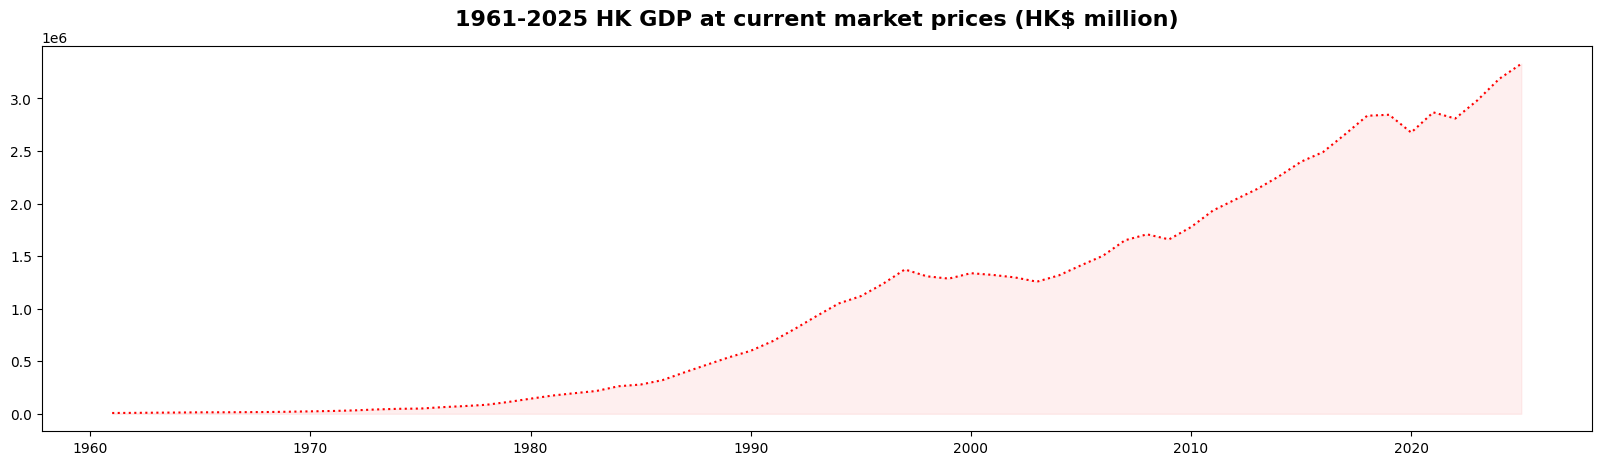

In [ ]:
import matplotlib.pyplot as plt
#Simple Timeseries line chart
plt.figure(figsize=(20, 5))
plt.plot(df_gdp_data['Year'],df_gdp_data['GDP_HKD_M'],color='r', linestyle='dotted',)
plt.fill_between(df_gdp_data['Year'], df_gdp_data['GDP_HKD_M'], color="#fa6969", alpha=0.1)
plt.title("1961-2025 HK GDP at current market prices (HK$ million)", fontsize=16, fontweight='bold', pad=15)

In [41]:
#Now, we try calculate yoy var %
df_gdp_data_yoy=df_gdp_data
#step 1, create a new column which select the previous record ~ last year
df_gdp_data_yoy['Last_year_GDP_HKD_M']= df_gdp_data_yoy['GDP_HKD_M'].shift(1)
#step 2, calculate yoy variance
df_gdp_data_yoy['GDP_yoy_var']=df_gdp_data_yoy['GDP_HKD_M'] - df_gdp_data_yoy['Last_year_GDP_HKD_M']
#step 3, calculate yoy %
df_gdp_data_yoy['GDP_yoy_percent']=df_gdp_data_yoy['GDP_yoy_var']/df_gdp_data_yoy['Last_year_GDP_HKD_M']
df_gdp_data_yoy

,Year,GDP_HKD_M,Last_year_GDP_HKD_M,GDP_yoy_var,GDP_yoy_percent
0,1961,7455.0,NaN,NaN,NaN
1,1962,8687.0,7455.0,1232.0,0.165258
2,1963,10427.0,8687.0,1740.0,0.200299
3,1964,11888.0,10427.0,1461.0,0.140117
4,1965,13953.0,11888.0,2065.0,0.173705
...,...,...,...,...,...
60,2021,2867973.0,2675793.0,192180.0,0.071822
61,2022,2808922.0,2867973.0,-59051.0,-0.020590
62,2023,2981210.0,2808922.0,172288.0,0.061336
63,2024,3186526.0,2981210.0,205316.0,0.068870


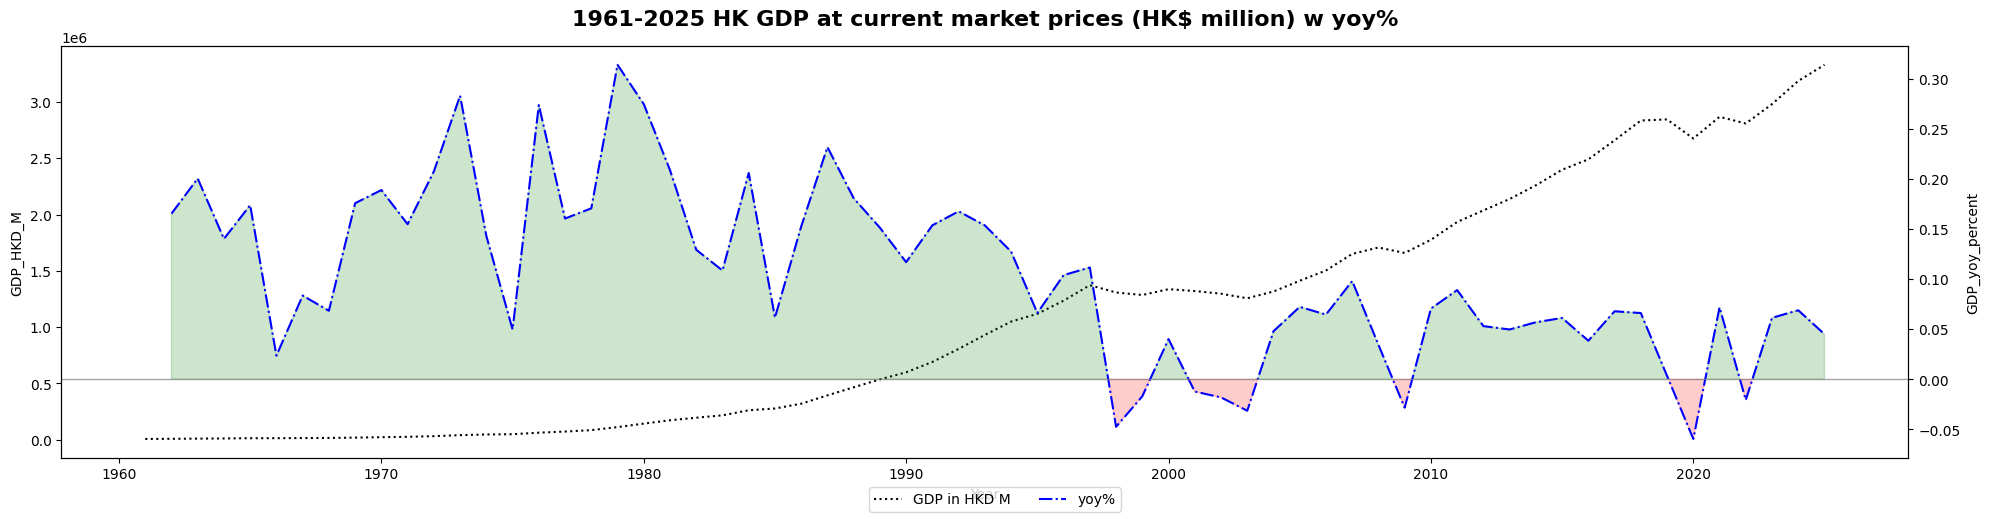

In [73]:
#Draw GDP vs GDP yoy% trend in one chart (use twinx)
fig, ax1=plt.subplots(figsize=(20, 5))
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP_HKD_M')
ax1.plot(df_gdp_data['Year'], df_gdp_data_yoy['GDP_HKD_M'],color='black', linestyle='dotted',label='GDP in HKD M')
ax2=ax1.twinx()
ax2.set_ylabel('GDP_yoy_percent')
ax2.plot(df_gdp_data['Year'], df_gdp_data_yoy['GDP_yoy_percent'],color='b', linestyle='dashdot',label='yoy%')
ax2.fill_between(df_gdp_data['Year'],df_gdp_data_yoy['GDP_yoy_percent'], 0, where=(df_gdp_data_yoy['GDP_yoy_percent']>=0),color='green',alpha=0.2,interpolate=True)
ax2.fill_between(df_gdp_data['Year'],df_gdp_data_yoy['GDP_yoy_percent'], 0, where=(df_gdp_data_yoy['GDP_yoy_percent']<=0),color='red',alpha=0.2,interpolate=True)
ax2.axhline(0,color='gray',linestyle='-',linewidth=1,alpha=0.7)
fig.tight_layout()
fig.legend(loc='lower center', ncols=2)
plt.title("1961-2025 HK GDP at current market prices (HK$ million) w yoy%", fontsize=16, fontweight='bold', pad=15)
plt.show()

In [82]:
#Now, we try calculate acceleration
#create a new column which select the previous growth rate and calculate acceleration
df_gdp_data_yoy['GDP_acceleration']= (df_gdp_data_yoy['GDP_yoy_percent'] - df_gdp_data_yoy['GDP_yoy_percent'].shift(1))
df_gdp_data_yoy

,Year,GDP_HKD_M,Last_year_GDP_HKD_M,GDP_yoy_var,GDP_yoy_percent,GDP_acceleration
0,1961,7455.0,NaN,NaN,NaN,NaN
1,1962,8687.0,7455.0,1232.0,0.165258,NaN
2,1963,10427.0,8687.0,1740.0,0.200299,0.035041
3,1964,11888.0,10427.0,1461.0,0.140117,-0.060182
4,1965,13953.0,11888.0,2065.0,0.173705,0.033588
...,...,...,...,...,...,...
60,2021,2867973.0,2675793.0,192180.0,0.071822,0.131304
61,2022,2808922.0,2867973.0,-59051.0,-0.020590,-0.092412
62,2023,2981210.0,2808922.0,172288.0,0.061336,0.081926
63,2024,3186526.0,2981210.0,205316.0,0.068870,0.007534


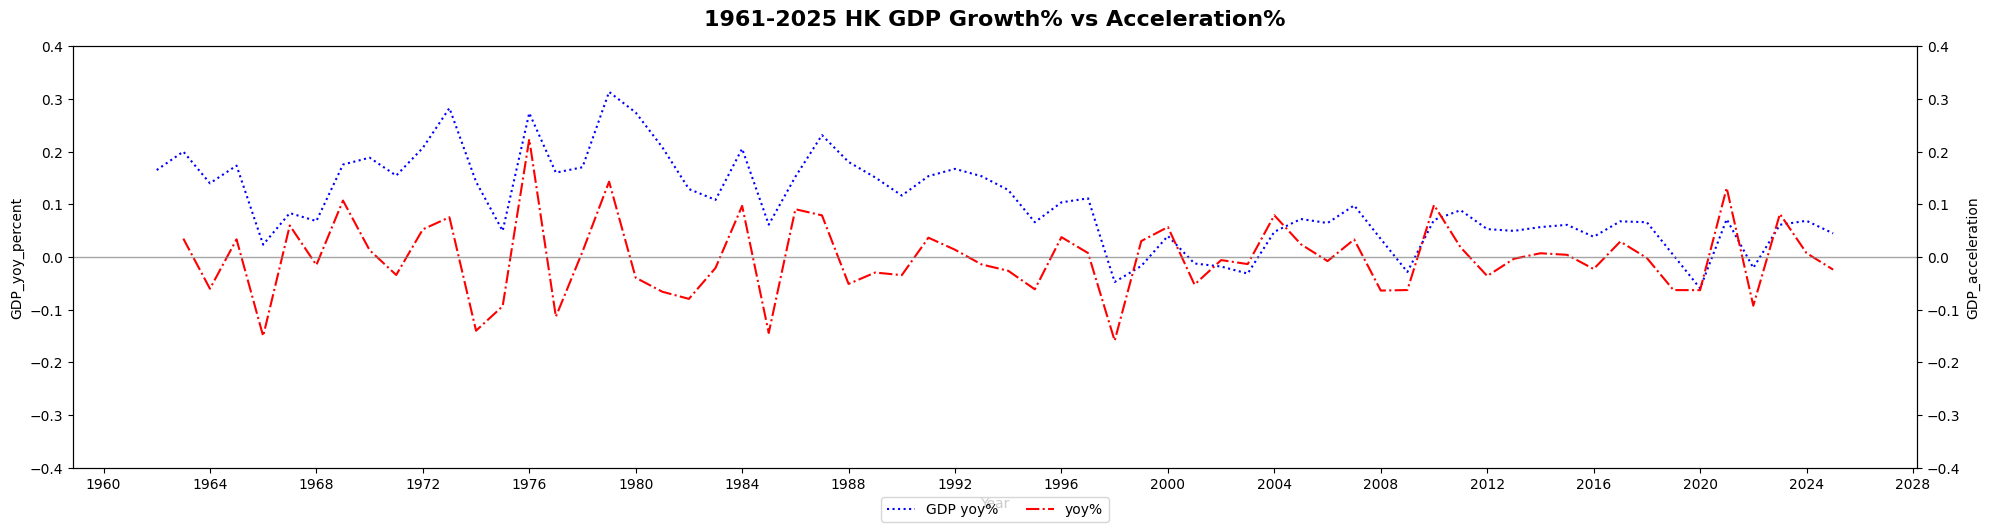

In [ ]:
#Draw GDP yoy% vs GDP acceleration trend in one chart (use twinx)
from matplotlib.ticker import MaxNLocator
fig, ax1=plt.subplots(figsize=(20, 5))
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP_yoy_percent')
ax1.plot(df_gdp_data['Year'], df_gdp_data_yoy['GDP_yoy_percent'],color='blue', linestyle='dotted',label='GDP yoy%')
ax2=ax1.twinx()
ax2.set_ylabel('GDP_acceleration')
ax2.plot(df_gdp_data['Year'], df_gdp_data_yoy['GDP_acceleration'],color='r', linestyle='dashdot',label='yoy%')
ax2.axhline(0,color='gray',linestyle='-',linewidth=1,alpha=0.7)
ax1.set_ylim(bottom=-0.4,top=0.4)
ax2.set_ylim(bottom=-0.4,top=0.4)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=20)) #MaxNLocator use to auto detect maximum label could be shown
fig.tight_layout()
fig.legend(loc='lower center', ncols=2)
plt.title("1961-2025 HK GDP Growth% vs Acceleration%", fontsize=16, fontweight='bold', pad=15)
plt.show()